# Bangla Handwriting Recognition · Lekha-CRNN · EVALUATE-ONLY (reuses a trained model, no training)
**One CRNN-CTC model reads single characters, multi-digit numbers and whole words.** A single glyph is just a sequence of length 1, so the two classifier models are not needed.

| Why v5 under-performed | Fix here |
|---|---|
| `LR = 1e-5` for every model (~100× too low for AdamW from scratch) | One-cycle LR, peak `2e-3`, warm-up, EMA |
| Label longer than the picture (canvas fixed at 256 px, text cut, label kept) | Width follows content, labels always match the image |
| 100-word closed vocabulary → the GRU memorises words | Random pseudo-words from valid syllable patterns + lexicon only for decoding |
| No whole-word augmentation, matra not tied to glyphs | Matra from each glyph's own headline, elastic / stroke / blur / noise |
| Sparse frame supervision | Exact per-glyph spans → auxiliary classifier loss (no teacher model) |
| 300 eval samples, exact match only | 1000+ samples, exact / CER / F1, real-glyph top-1/top-3/macro-F1, ECE, PASS/FAIL |

**This version does not train.** Attach the previous run's output as a second input (it must contain `model3.pt`, `data.npz`, `meta.csv`, `cl_flags.npy`); the notebook copies them, then calibrates, evaluates and exports (~10 min). It stops with a clear message if they are missing, so it can never start a 2-hour training by accident.

**Run:** add the dataset as input · GPU · Internet ON · *Save Version → Save & Run All*. Finished stages are skipped on re-run and training resumes from the last epoch.
Set `FAST=True` first for a ~10 min smoke test (tiny data, 2 epochs, own folder `fast/`), then set `FAST=False` for the real run.

## 0 · Setup

In [1]:
import subprocess, sys, importlib.metadata as md
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'onnx', 'onnxruntime', 'openpyxl',
                f'numpy=={md.version("numpy")}'], check=False)  # pin numpy so the install cannot break other packages

import os, json, math, random, time, shutil, inspect
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize

CFG = dict(
    DATA='/kaggle/input',   # searched recursively for the class folders 1..84 (+ optional "Form-based Marking.xlsx")
    WORDS=None,             # optional text file, one word per line: a bigger lexicon for decoding (text only)
    GOLDEN=None,            # optional folder of real canvas drawings named "<text>_<n>.png" (test only, never trained on)
    OUT='/kaggle/working', FAST=False, SEED=42, CLEAN=True,
    BS=64, STEPS=1500, EP=40, LR=2e-3, WORKERS=4,
)
if CFG['FAST']:  # smoke test only; writes to its own folder so the real run can never reuse its tiny cache
    CFG.update(BS=16, STEPS=20, EP=2, WORKERS=1, OUT=CFG['OUT'] + '/fast')
    print('*** FAST MODE: ~4% of writers, 2 epochs, results are meaningless. Set FAST=False for the real run. ***')
OUT = Path(CFG['OUT']); REL = OUT / 'release'
(OUT / 'ckpt').mkdir(parents=True, exist_ok=True); REL.mkdir(exist_ok=True)
os.chdir(OUT); sys.path.insert(0, str(OUT))
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = dict(device_type=DEV, dtype=torch.float16, enabled=DEV == 'cuda')
random.seed(CFG['SEED']); np.random.seed(CFG['SEED']); torch.manual_seed(CFG['SEED']); torch.backends.cudnn.benchmark = True
print(DEV, torch.__version__)

cuda 2.11.0+cu130


## 0b · Reuse the trained model
The "Held-out words" rows are **not valid** for a model trained before the lexicon split (it saw those words); glyph, number and pseudo-word rows are valid.

In [2]:
hits = list(Path('/kaggle/input').rglob('model3.pt'))                      # finds the attached previous output (can take ~30 s)
src = next((p.parent for p in hits if (p.parent / 'data.npz').exists()), None)
need = ['model3.pt', 'data.npz', 'meta.csv', 'cl_flags.npy']
assert src and all((src / f).exists() for f in need), f'Attach the previous run output (or a dataset made from it) as an Input. It must contain {need}.'
for f in need: shutil.copy(src / f, OUT / f)
print('reusing', src, '→ training is skipped')

reusing /kaggle/input/notebooks/imohammedali/bangla-hwr-model3-f → training is skipped


## 1 · `inference.py` — shipped with the model and imported here, so training and deployment cannot drift apart
Labels · preprocessing · CTC decoding (free, digits-only, lexicon) · `Recognizer`.
The 24 conjunct classes (folders 61–84) follow the class table in your v5 notebook; verify them against `class_grid.png` (section 3).

In [3]:
%%writefile inference.py
"""Bangla handwriting recognition with ONE CRNN-CTC model (characters, numbers, words).
Deployment needs only: numpy, opencv-python-headless, onnxruntime."""
import json, unicodedata
from pathlib import Path
import numpy as np, cv2

N = lambda s: unicodedata.normalize('NFC', s)
VOWELS = 'অ আ ই ঈ উ ঊ ঋ এ ঐ ও ঔ'.split()
CONSONANTS = 'ক খ গ ঘ ঙ চ ছ জ ঝ ঞ ট ঠ ড ঢ ণ ত থ দ ধ ন প ফ ব ভ ম য র ল শ ষ স হ ড় ঢ় য় ৎ ং ঃ ঁ'.split()
DIGITS = list('০১২৩৪৫৬৭৮৯')
COMPOUNDS = 'ক্ষ জ্ঞ ঞ্চ ঞ্ছ ঞ্জ ত্ত ত্র দ্ধ দ্ব ন্ত ন্দ ন্ধ ম্প ম্ফ ম্ব ম্ভ ম্ম ল্ক ল্গ ল্প ল্ট শ্চ ষ্ঠ স্ত'.split()
CLASSES = [N(c) for c in VOWELS + CONSONANTS + DIGITS + COMPOUNDS]       # folder k  ->  CLASSES[k-1]
assert len(CLASSES) == 84 == len(set(CLASSES))
KARS = ['\u09be', '\u09bf', '\u09c0', '\u09c1', '\u09c2', '\u09c3', '\u09c7', '\u09c8', '\u09d7']  # া ি ী ু ূ ৃ ে ৈ ৗ
PRE = {'\u09bf', '\u09c7', '\u09c8'}                 # ি ে ৈ are written before their consonant
VOCAB = ['<blank>'] + CLASSES + KARS                 # CTC tokens; class c has token id c+1
TID = {t: i for i, t in enumerate(VOCAB)}
DIG = [0] + [TID[d] for d in DIGITS]
_TOKS = sorted(VOCAB[1:], key=len, reverse=True)


def to_visual(word):
    """Unicode word -> tokens in writing order (ো = ে+া, ৌ = ে+ৗ). None if it uses symbols the model cannot write."""
    s, out, i = N(word).replace('\u09cb', '\u09c7\u09be').replace('\u09cc', '\u09c7\u09d7'), [], 0
    while i < len(s):
        t = next((t for t in _TOKS if s.startswith(t, i)), None)
        if t is None: return None
        out.insert(len(out) - 1, t) if t in PRE and out and out[-1] not in KARS else out.append(t)
        i += len(t)
    return out


def from_visual(toks):
    """Tokens in writing order -> Unicode text."""
    t, i = list(toks), 0
    while i < len(t) - 1:
        if t[i] in PRE and t[i + 1] not in KARS: t[i], t[i + 1] = t[i + 1], t[i]; i += 2
        else: i += 1
    return N(''.join(t).replace('\u09c7\u09be', '\u09cb').replace('\u09c7\u09d7', '\u09cc'))


def ink(g):
    """Gray/BGR/RGBA image -> uint8, bright strokes on black, faint paper noise removed."""
    g = np.asarray(g)
    if g.ndim == 3:
        g = g[..., 3] if g.shape[2] == 4 and g[..., 3].min() < 255 else cv2.cvtColor(g[..., :3], cv2.COLOR_BGR2GRAY)
    g = g.astype(np.uint8)
    if g.mean() > 127: g = 255 - g
    return np.where(g > 50, g, 0).astype(np.uint8)


def crop(g):
    ys, xs = np.nonzero(g)
    return g[ys.min():ys.max() + 1, xs.min():xs.max() + 1] if len(xs) else None


def prep(g, size=64, fit=52, info=False):
    """One character -> canonical 64x64: cropped, deslanted, longest side 52, centred (used to build the glyph bank)."""
    g = crop(ink(g)); z = np.zeros((size, size), np.uint8)
    if g is None or (g > 0).sum() < 5: return (z, 0.) if info else z
    m = cv2.moments(g); sk = float(np.clip(m['mu11'] / (m['mu02'] + 1e-6), -.4, .4))
    h, w = g.shape; pad = int(abs(sk) * h) + 1
    g = crop(cv2.warpAffine(g, np.float32([[1, -sk, pad + sk * h / 2], [0, 1, 0]]), (w + 2 * pad, h)))
    h, w = g.shape; s = fit / max(h, w)
    g = cv2.resize(g, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    y, x = (size - g.shape[0]) // 2, (size - g.shape[1]) // 2; z[y:y + g.shape[0], x:x + g.shape[1]] = g
    return (z, sk) if info else z


def prep_line(g, H=64, maxw=512):
    """Model input for ANY drawing (character, number, word): height 64, width a multiple of 4 (16..512)."""
    g = crop(ink(g))
    if g is None: return np.zeros((H, 16), np.uint8)
    g = cv2.copyMakeBorder(g, 4, 4, 4, 4, cv2.BORDER_CONSTANT)
    w = min(maxw, max(16, round(g.shape[1] * H / g.shape[0])))
    return cv2.resize(g, (w - w % 4, H), interpolation=cv2.INTER_AREA)


def softmax(z, T=1.0):
    z = np.asarray(z, np.float64) / T; z = np.exp(z - z.max(-1, keepdims=True))
    return z / z.sum(-1, keepdims=True)


def greedy(P):
    """Best-path CTC decoding of (T, V) probabilities; token 0 is the blank."""
    a = np.asarray(P).argmax(-1); keep = (a != 0) & np.r_[True, a[1:] != a[:-1]]
    return tuple(a[keep].tolist())


def beam(P, prefixes=None, words=None, width=10, prune=1e-3):
    """CTC prefix beam search, optionally limited to a lexicon. Returns [(tokens, relative mass)], best first."""
    beams = {(): (1.0, 0.0)}
    for p in P:
        nxt, cs = {}, [c for c in np.nonzero(p > prune)[0] if c]
        def add(k, b=0., nb=0.):
            ob, onb = nxt.get(k, (0., 0.)); nxt[k] = (ob + b, onb + nb)
        for pre, (pb, pnb) in beams.items():
            add(pre, b=(pb + pnb) * p[0])
            for c in cs:
                new = pre + (c,)
                if pre and pre[-1] == c: add(pre, nb=pnb * p[c]); ext = pb * p[c]
                else: ext = (pb + pnb) * p[c]
                if prefixes is None or new in prefixes: add(new, nb=ext)
        best = sorted(nxt.items(), key=lambda kv: -sum(kv[1]))[:width]
        z = sum(sum(v) for _, v in best) or 1.
        beams = {k: (b / z, nb / z) for k, (b, nb) in best}
    return sorted(((k, b + nb) for k, (b, nb) in beams.items() if words is None or k in words), key=lambda kv: -kv[1])


def ctc_prob(P, lab):
    """True probability (all alignments) that the model reads exactly `lab`."""
    if not lab: return float(np.prod(P[:, 0]))
    ext = np.zeros(2 * len(lab) + 1, np.int64); ext[1::2] = lab
    skip = np.zeros(len(ext), bool); skip[2:] = (ext[2:] != 0) & (ext[2:] != ext[:-2])
    a = np.zeros(len(ext)); a[0] = P[0, 0]; a[1] = P[0, ext[1]]
    for t in range(1, len(P)):
        n = a.copy(); n[1:] += a[:-1]; n[2:] += np.where(skip[2:], a[:-2], 0.); a = n * P[t, ext]
    return float(a[-1] + a[-2])


def make_lex(words):
    ids = [tuple(TID[t] for t in v) for v in map(to_visual, words) if v]
    return set(ids), {w[:i] for w in ids for i in range(1, len(w) + 1)}


def candidates(P, mode, lex=None):
    """Candidate readings with their TRUE probabilities. mode: 'number' (digits only) or 'word'."""
    if mode == 'number':
        Q = np.zeros_like(P); Q[:, DIG] = P[:, DIG]; Q /= Q.sum(1, keepdims=True)
        c = [k for k, _ in beam(Q, width=8)]
    else:
        c = [k for k, _ in beam(P, width=10)]
        if lex: c += [k for k, _ in beam(P, lex[1], lex[0], width=10)[:4]]
    return [(k, ctc_prob(P, k)) for k in dict.fromkeys(c) if k]


def rank(cands, lex=None, bonus=3.0, k=3):
    """Best-first: log-probability, plus `bonus` for lexicon words (a soft lexicon prior, never a hard limit)."""
    key = lambda c: np.log(c[1] + 1e-12) + (bonus if lex and c[0] in lex[0] else 0.)
    return sorted(cands, key=key, reverse=True)[:k]


def char_probs(P):
    """Single glyph: peak evidence per class (84,) and the normalised distribution."""
    S = P[:, 1:1 + len(CLASSES)].max(0); return S, S / S.sum()


class Recognizer:
    """Loads release/ and reads a character, a number or a whole word with one ONNX model.
    predict(img, mode='auto'|'char'|'number'|'word') -> {text, top3, confidence, decision: accept|suggest|reject}"""

    def __init__(self, d='.'):
        import onnxruntime as ort
        d = Path(d); self.c = json.loads((d / 'config.json').read_text(encoding='utf-8'))
        so = ort.SessionOptions(); so.intra_op_num_threads = 1
        self.m = ort.InferenceSession(str(d / self.c['model']), so, providers=['CPUExecutionProvider'])
        self.lex = make_lex((d / 'lexicon.txt').read_text(encoding='utf-8').split())

    def raw(self, img):
        """One forward pass: CTC logits (T, V) and classifier-head logits (84,)."""
        o = self.m.run(None, {'x': prep_line(img)[None, None].astype(np.float32) / 255}); return o[0][0], o[1][0]

    def predict(self, img, mode='auto'):
        c, none = self.c, dict(text='', top3=[], confidence=0., decision='reject')
        if crop(ink(img)) is None: return none
        lg, ax = self.raw(img); P = softmax(lg, c['T']); free = greedy(P)
        if not free: return none
        if mode == 'auto': mode = 'char' if len(free) == 1 else 'number' if all(VOCAB[t] in DIGITS for t in free) else 'word'
        if mode == 'char':
            S, p1 = char_probs(softmax(lg, c['Tc'])); wa = c.get('wa', 0.)
            p = (1 - wa) * p1 + wa * softmax(ax, c.get('Ta', 1.)); top = np.argsort(-p)[:3]; conf = float(p[top[0]])
            dec = 'reject' if S.max() < c['tau']['ink'] else 'accept' if conf >= c['tau']['char'] else 'suggest'
            return dict(text=CLASSES[top[0]], top3=[(CLASSES[i], float(p[i])) for i in top], confidence=conf, decision=dec)
        lex = self.lex if mode == 'word' else None
        r = rank(candidates(P, mode, lex), lex, c['bonus'])
        if not r: return none
        txt = lambda k: from_visual([VOCAB[i] for i in k])
        best, conf = r[0]
        ok = conf >= c['tau'][mode] and (mode == 'number' or best in self.lex[0] or greedy(P) == best)
        return dict(text=txt(best), top3=[(txt(k), float(s)) for k, s in r], confidence=float(conf), decision='accept' if ok else 'suggest')

Writing inference.py


In [4]:
import importlib, inference; importlib.reload(inference)
from inference import *

# Lexicon (text only) is used for DECODING and as one of the training sources; words with symbols outside the 84 classes are dropped.
WORDS = '''জল ঘর কলম বই ফল পথ মন বন রথ নখ দশ শত চল বল দল সরল গরম নরম তরল কমল সফল নকল ফসল বদল শহর খবর নজর বছর
অমর অলস ঈগল উৎস একক ওজন ঔষধ কদম গজল চরণ জনম তপন দমন নয়ন পবন ভবন মরণ যখন লবণ শয়ন সড়ক হরণ অঞ্চল সুন্দর বন্দর
মানুষ কথা বাড়ি পাখি নদী আকাশ বাতাস সকাল বিকাল রাত দিন ফুল পাতা মাটি পানি আলো ছায়া মেঘ তারা সূর্য সাগর পাহাড় গাছ
ভালো মন্দ সুখ দুঃখ হাসি গান কবিতা ছবি দেশ ভাষা বাংলা জীবন সময় কাজ খেলা খাবার ভাত মাছ দুধ চিনি মধু তেল নুন
জগৎ আম আজ আর এক ইট উট ঋণ ঈদ মা বাবা ভাই বোন নৌকা দিনরাত লাল নীল কালো সাদা হলুদ সবুজ বড় ছোট কুকুর বিড়াল গরু ছাগল
হাতি বাঘ সিংহ সাগর শীত জামা জুতা টাকা বাজার দোকান গাড়ি রেল খাতা কাগজ নাচ মাঠ বাগান পুকুর ঘড়ি চাবি দরজা জানালা টেবিল
চেয়ার বালিশ সমাজ পরিবার ভালোবাসা আশা সোনা রূপা লোহা মাথা চোখ কান নাক মুখ পা হাত পেট বুক শরীর রোগ শিশু রাজা রানি কবি
উপহার বছর মাস ঢাকা খুলনা রাজশাহী সিলেট বরিশাল রংপুর মেলা পিঠা চা ঢোল ছুটি চিঠি ডাক পিতা মাতা ঘুম'''.split()
if CFG['WORDS']: WORDS += Path(CFG['WORDS']).read_text(encoding='utf-8').split()
LEX = sorted({N(w) for w in WORDS if '\u0981' not in w and to_visual(w)})     # ঁ sits above a letter: not renderable as a glyph
isA = lambda ids: not any(VOCAB[t] in KARS for t in ids)      # tier A: dataset glyphs only · tier B: needs vowel signs
LEX_A = [w for w in LEX if isA([TID[t] for t in to_visual(w)])]
LEXS = make_lex(LEX)                                                         # decoding lexicon = all words
LEX_TEST, LEX_VAL = LEX[0::5], LEX[2::10]                                    # held out: the model never trains on these words
LEX_TRAIN = [w for w in LEX if w not in set(LEX_TEST) | set(LEX_VAL)]
assert all(from_visual(to_visual(w)) == w for w in LEX)
print(f'{len(CLASSES)} classes · {len(VOCAB)} tokens · lexicon {len(LEX)} words (train {len(LEX_TRAIN)} · val {len(LEX_VAL)} · test {len(LEX_TEST)})')
print('মানুষ ->', to_visual('মানুষ'), '| বিড়াল ->', to_visual('বিড়াল'))

84 classes · 94 tokens · lexicon 189 words (train 132 · val 19 · test 38)
মানুষ -> ['ম', 'া', 'ন', 'ু', 'ষ'] | বিড়াল -> ['ি', 'ব', 'ড়', 'া', 'ল']


## 2 · Data: load, parse writers, clean (V1), split by writer
Filename = `district_institute_gender_age_date_form_class` — one form is one writer. Files whose name-class disagrees with the folder are dropped.
Duplicates are removed **within** (class, writer) only: a coarse global hash would delete legitimately similar simple glyphs of different people.

166058 images · 1990 writers · 84 classes · quality table: 2000 forms
{'train': 132669, 'val': 16641, 'test': 16628} | writers: {'test': 199, 'train': 1592, 'val': 199}


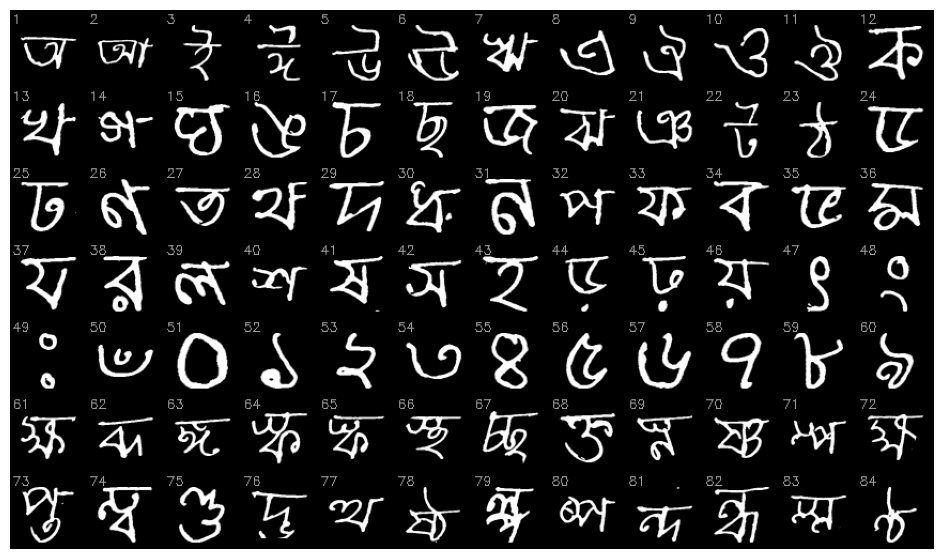

conjunct folders: {61: 'ক্ষ', 62: 'জ্ঞ', 63: 'ঞ্চ', 64: 'ঞ্ছ', 65: 'ঞ্জ', 66: 'ত্ত', 67: 'ত্র', 68: 'দ্ধ', 69: 'দ্ব', 70: 'ন্ত', 71: 'ন্দ', 72: 'ন্ধ', 73: 'ম্প', 74: 'ম্ফ', 75: 'ম্ব', 76: 'ম্ভ', 77: 'ম্ম', 78: 'ল্ক', 79: 'ল্গ', 80: 'ল্প', 81: 'ল্ট', 82: 'শ্চ', 83: 'ষ্ঠ', 84: 'স্ত'}


In [5]:
def find_assets():
    root = next((Path(r) for r, d, _ in os.walk(CFG['DATA']) if {'1', '84'} <= set(d)), None)
    assert root, f'No folder with class folders 1..84 under {CFG["DATA"]}'
    xl = next((p for b in (root, root.parent, root.parent.parent) for p in b.glob('*.xlsx') if 'form' in p.name.lower()), None)
    return root, xl

def quality_map(xl):
    """Form-based Marking.xlsx -> {form serial: average mark (0-5)}; {} if unavailable."""
    try:
        t = pd.read_excel(xl); t.columns = [str(c).strip() for c in t.columns]
        f = next(c for c in t.columns if 'form' in c.lower()); a = next(c for c in t.columns if 'average' in c.lower())
        return dict(zip(pd.to_numeric(t[f], errors='coerce').fillna(-1).astype(int), pd.to_numeric(t[a], errors='coerce')))
    except Exception as e: print('form-quality table unavailable:', e); return {}

ROOT, XL = find_assets(); QM = quality_map(XL) if XL else {}
rows = []
for f in ROOT.glob('*/*'):
    if not (f.parent.name.isdigit() and f.suffix.lower() in ('.png', '.jpg', '.jpeg', '.bmp')): continue
    p, k = f.stem.split('_'), int(f.parent.name)
    if len(p) >= 7 and p[6].isdigit() and int(p[6]) != k: continue
    rows.append((str(f), k - 1, '_'.join(p[:6]) if len(p) >= 6 else f.stem, *(p[i] if len(p) > i else '' for i in (0, 2, 3, 5))))
df = pd.DataFrame(rows, columns=['path', 'y', 'writer', 'district', 'gender', 'age', 'form'])
df['quality'] = pd.to_numeric(df.form, errors='coerce').map(QM).fillna(3.0)
print(f'{len(df)} images · {df.writer.nunique()} writers · {df.y.nunique()} classes · quality table: {len(QM)} forms')
if CFG['FAST']:
    wr = df.writer.drop_duplicates(); df = df[df.writer.isin(wr.sample(min(len(wr), max(30, len(wr) // 25)), random_state=0))].reset_index(drop=True)

def load(p):
    g = cv2.imread(p, cv2.IMREAD_GRAYSCALE); g = ink(g if g is not None else np.zeros((64, 64), np.uint8))
    c, sk = prep(g, info=True); return c, sk, (g > 0).mean()

if (OUT / 'data.npz').exists(): D = dict(np.load(OUT / 'data.npz')); df = pd.read_csv(OUT / 'meta.csv', dtype={'writer': str})
else:
    with ThreadPoolExecutor(16) as ex: R = list(ex.map(load, df.path, chunksize=256))
    X, SK, INK = (np.stack([r[i] for r in R]) for i in range(3)); del R
    key = pd.Series([hash((int(y), w, (cv2.resize(x, (32, 32), interpolation=cv2.INTER_AREA) > 64).tobytes())) for y, w, x in zip(df.y, df.writer, X)])
    keep = ((INK > .01) & ~key.duplicated()).to_numpy()
    print(f'V1: removed {(INK <= .01).sum()} blanks and {int((~keep).sum() - (INK <= .01).sum())} duplicates')
    df, X, SK = df[keep].reset_index(drop=True), X[keep], SK[keep]
    w = df.writer.drop_duplicates().sample(frac=1, random_state=CFG['SEED']).to_numpy()
    df['split'] = df.writer.map({k: 'train' if i < .8 * len(w) else 'val' if i < .9 * len(w) else 'test' for i, k in enumerate(w)})
    with ThreadPoolExecutor(16) as ex: S = np.stack(list(ex.map(lambda x: skeletonize(x > 64), X, chunksize=256))).astype(np.uint8)
    D = dict(X=X, SK=SK, S=S, SW=(X > 64).sum((1, 2)) / np.maximum(S.sum((1, 2)), 1)); np.savez(OUT / 'data.npz', **D); df.to_csv(OUT / 'meta.csv', index=False)

X, SK, S, SW, Y = D['X'], D['SK'], D['S'], D['SW'], df.y.to_numpy()
WR = pd.factorize(df.writer)[0]; QW = pd.Series(df.quality.to_numpy()).groupby(WR).first().to_dict()
idx = {s: np.flatnonzero(df.split.to_numpy() == s) for s in ('train', 'val', 'test')}
tr, va, te = idx['train'], idx['val'], idx['test']
print({k: len(v) for k, v in idx.items()}, '| writers:', df.groupby('split').writer.nunique().to_dict())

# one sample per class: compare the numbers with your class table (folders 61-84 are the conjuncts)
grid = np.zeros((7 * 72, 12 * 72), np.uint8)
for c in range(84):
    j = np.flatnonzero(Y == c)
    if len(j): grid[c // 12 * 72 + 8:c // 12 * 72 + 72, c % 12 * 72 + 4:c % 12 * 72 + 68] = X[j[0]]
    cv2.putText(grid, str(c + 1), (c % 12 * 72 + 2, c // 12 * 72 + 12), cv2.FONT_HERSHEY_SIMPLEX, .4, 160, 1)
cv2.imwrite('class_grid.png', grid); plt.figure(figsize=(12, 7)); plt.imshow(grid, cmap='gray'); plt.axis('off'); plt.show()
print('conjunct folders:', {i + 1: CLASSES[i] for i in range(60, 84)})

## 3 · Dataset engineering
| Version | What | Why |
|---|---|---|
| V1 | Blanks, within-writer duplicates, likely mislabels (2-fold confident learning with a throw-away CNN) | Label noise caps accuracy |
| V2 | Canonical glyphs: crop, deslant, fit, centre (`prep`) | Learn the shape, not the pen |
| V3 | Canvas-style: skeleton re-drawn with a random brush (at composition time) | The app's input is a touch canvas, not a scan |
| V4 | Writer-style transfer: slant and pen width of another writer applied to the whole word | More distinct "writers" |
| V5 | Counterfactual glyphs: remove or add the deciding dot (ড়↔ড, ঢ়↔ঢ, য়↔য, র↔ব) | Targets the commonest confusions |
| V6 | Vowel signs: া cut from the same writer's আ, the others drawn as jittered strokes in that writer's pen width | The dataset has none |
| V7 | Reject samples (scribbles, fragments, blanks) with an **empty** label | Output nothing → "please redraw" |
| V8 | Same-writer numbers, lexicon words, random pseudo-words, single glyphs (next sections) | Whole-word reading from isolated glyphs |

In [6]:
gpu = lambda a: torch.from_numpy(np.ascontiguousarray(a)).to(DEV)

def cnn():
    cbr = lambda i, o: [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True), nn.MaxPool2d(2)]
    return nn.Sequential(*cbr(1, 32), *cbr(32, 64), *cbr(64, 128), *cbr(128, 256), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 84)).to(DEV)

def train_cnn(ids, epochs, lr=2e-3):
    m, Xg, yg = cnn(), gpu(X[ids]), gpu(Y[ids]); bs = min(256, max(8, len(ids) // 4)); n = len(ids) // bs
    opt = torch.optim.AdamW(m.parameters(), lr, weight_decay=.05); sc = torch.amp.GradScaler(enabled=AMP['enabled'])
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * n)
    for _ in range(epochs):
        m.train(); p = torch.randperm(len(ids), device=DEV)
        for i in range(n):
            j = p[i * bs:(i + 1) * bs]
            with torch.autocast(**AMP): loss = F.cross_entropy(m(Xg[j][:, None].float() / 255), yg[j])
            opt.zero_grad(); sc.scale(loss).backward(); sc.step(opt); sc.update(); sch.step()
    return m.eval()

@torch.no_grad()
def cnn_probs(m, A, bs=1024):
    return torch.cat([m(gpu(A[j:j + bs])[:, None].float() / 255).softmax(1).cpu() for j in range(0, len(A), bs)])

# V1: mislabel flags from out-of-fold predictions
if (OUT / 'cl_flags.npy').exists(): flag = np.load(OUT / 'cl_flags.npy')
elif CFG['CLEAN']:
    half = np.random.default_rng(0).random(len(tr)) < .5; P = np.zeros((len(tr), 84), np.float32)
    for f in (0, 1):
        m = train_cnn(tr[half != f], 1 if CFG['FAST'] else 4); P[half == f] = cnn_probs(m, X[tr[half == f]]).numpy()
    flag = (P.argmax(1) != Y[tr]) & (P.max(1) > .9) & (P[np.arange(len(tr)), Y[tr]] < .05); np.save(OUT / 'cl_flags.npy', flag)
else: flag = np.zeros(len(tr), bool)
print(f'V1: {flag.sum()} likely mislabels removed from train'); trc = tr[~flag]

# V5: counterfactual glyphs, appended to the glyph bank under their new class
def split_dot(g):
    n, lab, st, cen = cv2.connectedComponentsWithStats((g > 64).astype(np.uint8), 8)
    if n < 3: return None
    k = 1 + st[1:, 4].argmin()
    if st[k, 4] > .08 * st[1:, 4].sum() or cen[k, 1] < .55 * g.shape[0]: return None
    return g * (lab != k), g * (lab == k)

def counterfactuals(cap=1500, rng=np.random.default_rng(1)):
    out = []
    for dotted, plain in [('ড়', 'ড'), ('ঢ়', 'ঢ'), ('য়', 'য'), ('র', 'ব')]:
        cd, cp = CLASSES.index(N(dotted)), CLASSES.index(N(plain)); dots = []
        for i in trc[Y[trc] == cd][:cap]:
            r = split_dot(X[i])
            if r: out.append((prep(r[0]), cp, i)); dots.append(crop(r[1]))
        for i in trc[Y[trc] == cp][:cap if dots else 0]:
            g, d = X[i].copy(), dots[rng.integers(len(dots))]; ys_, xs_ = np.nonzero(g)
            y0 = min(ys_.max() + 3, 64 - d.shape[0]); x0 = int(np.clip(xs_.mean() - d.shape[1] / 2, 0, 64 - d.shape[1]))
            np.maximum(g[y0:y0 + d.shape[0], x0:x0 + d.shape[1]], d, out=g[y0:y0 + d.shape[0], x0:x0 + d.shape[1]]); out.append((prep(g), cd, i))
    return out

cf = counterfactuals(); n0 = len(X)
if cf:
    Xc = np.stack([c[0] for c in cf]); src = np.array([c[2] for c in cf]); Sc = np.stack([skeletonize(x > 64) for x in Xc]).astype(np.uint8)
    X, S = np.concatenate([X, Xc]), np.concatenate([S, Sc]); Y, WR = np.r_[Y, [c[1] for c in cf]], np.r_[WR, WR[src]]
    SW, SK = np.r_[SW, SW[src]], np.r_[SK, SK[src]]
TRAIN_IDS = np.r_[trc, np.arange(n0, len(X))]
print(f'V5: {len(X) - n0} counterfactual glyphs · glyph bank: {len(TRAIN_IDS)} train glyphs')

V1: 466 likely mislabels removed from train
V5: 8088 counterfactual glyphs · glyph bank: 140291 train glyphs


## 4 · Synthetic sequences (V3, V4, V6, V7, V8)
One writer per sample · glyphs sit on a shared headline (matra) found from each glyph's own image · vowel signs placed relative to their consonant ·
labels in **writing order** (ি is written before its consonant) and converted back to Unicode by `from_visual` · the picture is never cut, so image and label always match.

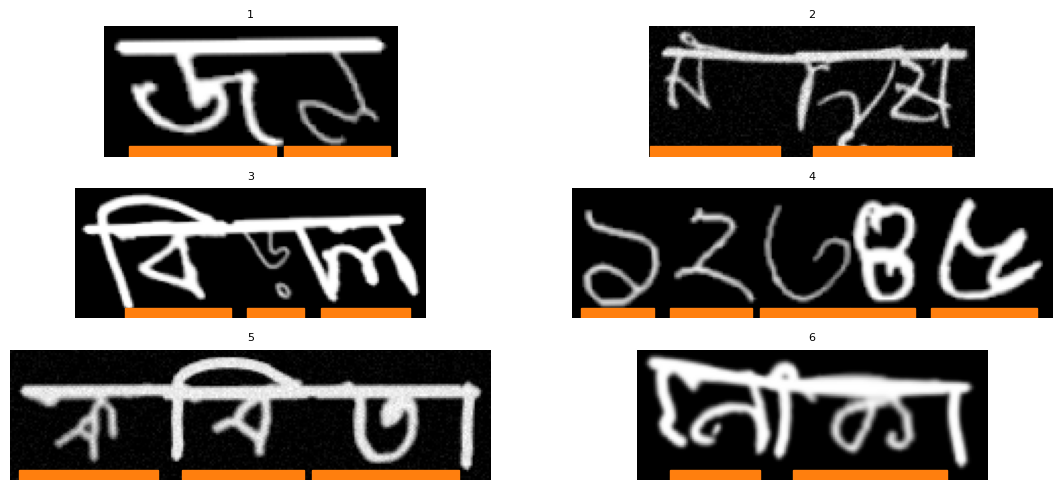

{1: 'জল', 2: 'মানুষ', 3: 'বিড়াল', 4: '১২৩৪৫', 5: 'কবিতা', 6: 'নৌকা'}


In [7]:
AA, I, II, U, UU, RI, E_, AI, AU = KARS
BELOW = {U, UU, RI}
SIGNS = ['া', 'ি', 'ী', 'ু', 'ূ', 'ৃ', 'ে', 'ৈ', 'ো', 'ৌ']
CONS = [N(c) for c in CONSONANTS[:35]]; CONJ = [N(c) for c in COMPOUNDS]; MODS = [N(c) for c in 'ংঃৎ']; VOW = [N(c) for c in VOWELS]
MIX = {0: dict(num=.30, char=.20, lex=.25, pseudo=.20, rej=.05), 1: dict(num=.25, char=.18, lex=.22, pseudo=.30, rej=.05),
       2: dict(num=.22, char=.20, lex=.20, pseudo=.33, rej=.05)}                    # curriculum: simple -> full
LENP = [.06, .18, .20, .20, .14, .10, .07, .05]                                     # number length 1..8
BRUSH = {k: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)) for k in (2, 3, 4)}
EL = np.array(KARS)

def reslant(g, sk):
    """Re-apply a glyph's own measured slant (inverse of the deslanting in `prep`): approximates the original, un-normalised image."""
    h, w = g.shape; pad = int(abs(sk) * h) + 1
    return cv2.warpAffine(g, np.float32([[1, sk, pad - sk * h / 2], [0, 1, 0]]), (w + 2 * pad, h))

def kar_strokes(k, hw):
    """Vowel-sign strokes in units of glyph height. x: from the sign's slot (from the host for signs below); y: 0 = headline, 1 = host bottom."""
    e = [(.25, 0), (.08, .25), (.22, .5), (.08, .75), (.25, .95)]
    return {AA: [[(.15, 0), (.15, 1)]], I: [[(.15, 1), (.15, 0), (.25, -.35), (.3 + .5 * hw, -.42), (.3 + .9 * hw, -.15)]],
            II: [[(.15, 1), (.15, 0), (.05, -.35), (-.5 * hw, -.42), (-.9 * hw, -.15)]], E_: [e],
            AI: [e, [(.05, -.05), (.15, -.3), (.3, -.18)]], AU: [[(.15, 1), (.15, 0)], [(.15, 0), (.25, -.3), (.35, -.12)]],
            U: [[(.5 * hw, .95), (.35 * hw, 1.2), (.55 * hw, 1.38), (.75 * hw, 1.18)]],
            UU: [[(.5 * hw, .95), (.3 * hw, 1.18), (.6 * hw, 1.3), (.35 * hw, 1.48), (.7 * hw, 1.45)]],
            RI: [[(.55 * hw, .95), (.4 * hw, 1.15), (.65 * hw, 1.28), (.45 * hw, 1.45)]]}[k]

def chaikin(p, n=2):
    for _ in range(n):
        q, r = .75 * p[:-1] + .25 * p[1:], .25 * p[:-1] + .75 * p[1:]
        p = np.vstack([p[:1], np.stack([q, r], 1).reshape(-1, 2), p[-1:]])
    return p

def headline(g):
    rows = (g > 64).sum(1); r = int(rows[:max(1, int(.35 * len(rows)))].argmax()); return r, rows[r] > .5 * g.shape[1]

def pseudo(rng, level):
    """Random but valid syllable pattern: [vowel | consonant/conjunct (+ vowel sign)]* (+ ং ঃ ৎ). Forces glyph reading, not word memorising."""
    out = ''
    for k in range(int(rng.integers(1, 5))):
        if k == 0 and rng.random() < .12: out += VOW[rng.integers(len(VOW))]; continue
        out += CONJ[rng.integers(24)] if level >= 2 and rng.random() < .15 else CONS[rng.integers(len(CONS))]
        if level >= 1 and rng.random() < .55: out += SIGNS[rng.integers(len(SIGNS))]
    return out + (MODS[rng.integers(3)] if rng.random() < .1 else '')

class Synth:
    """sample(kind=None) -> (image, token ids, spans [(class, frame0, frame1)], text, kind)"""
    def __init__(s, ids, seed=0, level=2, aug=True, pool=None):
        s.by, s.cls = {}, {}
        for i in ids: s.by.setdefault(WR[i], {}).setdefault(Y[i], []).append(i); s.cls.setdefault(Y[i], []).append(i)
        s.writers, s.level, s.aug, s.rng = list(s.by), level, aug, np.random.default_rng(seed)
        g = lambda a: pd.Series(a[ids]).groupby(WR[ids]).median()
        s.pen, s.slant = g(SW).to_dict(), g(SK).to_dict(); s.style = [(s.slant[w], s.pen[w] / np.median(list(s.pen.values()))) for w in s.writers]
        s.clean = [w for w in s.writers if QW.get(w, 3.) >= 2.5] or s.writers
        s.pool = pool or LEX_TRAIN; s.poolA = [w for w in s.pool if isA([TID[t] for t in to_visual(w)])] or s.pool

    def sample(s, kind=None):
        for _ in range(5):
            try: return s._sample(kind)
            except Exception as e: s.fails, s.last = getattr(s, 'fails', 0) + 1, repr(e)
        raise RuntimeError(f'sample() failed 5 times in a row: {s.last}')

    def _sample(s, kind=None):
        r, m = s.rng, MIX[s.level]; kind = kind or r.choice(list(m), p=list(m.values()))
        if kind == 'rej': return (*s.reject(), '', kind)
        if kind == 'num': text = ''.join(r.choice(DIGITS, int(r.choice(8, p=LENP)) + 1))
        elif kind == 'char':
            c = int(r.integers(84)); text = CLASSES[c]
            if r.random() < .5: return (*s.direct(c), text, kind)                  # half: a glyph exactly as the glyph test feeds it
        elif kind == 'lex': pool = s.poolA if s.level == 0 else s.pool; text = pool[r.integers(len(pool))]
        else: text = pseudo(r, s.level)
        return (*s.render(text), text, kind)

    def direct(s, c):
        """Single real glyph as the glyph test feeds it: tight crop, upright or in its original slant, usually lightly augmented."""
        r = s.rng; w = s.writers[r.integers(len(s.writers))]
        L = s.by[w].get(c) or s.cls.get(c) or s.cls[next(iter(s.cls))]; i = L[r.integers(len(L))]
        g = cv2.GaussianBlur(cv2.dilate(S[i] * 255, BRUSH[int(r.choice((2, 3, 4)))]), (3, 3), 0) if s.aug and r.random() < .3 else X[i]
        if r.random() < .5: g = reslant(g, float(SK[i]))
        img = prep_line(g); img = s.finish(img) if r.random() < .7 else img
        return img, [c + 1], [(c, 0, img.shape[1] // 4 - 1)]

    def glyph(s, w, c, h):
        r, L = s.rng, s.by[w].get(c) or s.cls.get(c) or s.cls[next(iter(s.cls))]; i = L[r.integers(len(L))]
        g = cv2.GaussianBlur(cv2.dilate(S[i] * 255, BRUSH[int(r.choice((2, 3, 4)))]), (3, 3), 0) if s.aug and r.random() < .3 else X[i]   # V3
        g = crop(g); g = g if g is not None else crop(X[i]); return i, cv2.resize(g, (max(4, min(int(1.8 * h), round(g.shape[1] * h / g.shape[0]))), h), interpolation=cv2.INTER_AREA)

    def aa(s, w, h):  # V6: the real া stroke = right part of the same writer's আ
        L = s.by[w].get(CLASSES.index(N('আ'))); g = crop(X[L[0]]) if L else None; g = crop(g[:, int(.68 * g.shape[1]):]) if g is not None else None
        return None if g is None or g.shape[1] > .5 * g.shape[0] else cv2.resize(g, (max(2, round(g.shape[1] * h / g.shape[0])), h))

    def render(s, text):
        r, toks = s.rng, to_visual(text) or ['ক']; is_num = all(k in DIGITS for k in toks)
        pool = s.clean if s.level == 0 and r.random() < .7 else s.writers; w = pool[r.integers(len(pool))]
        h, HL = int(r.integers(38, 50)), 44
        t = max(2, round(s.pen.get(w, 4) * h / 52 * r.uniform(.8, 1.2))); lo = -.12 if s.level >= 2 and not is_num else .02
        items, x, prev = [], 40, None
        for k in toks:
            if k in BELOW: items.append(dict(k=k, x0=x, x1=x, m=False)); continue
            if k in KARS:
                aa = s.aa(w, h) if k == AA and r.random() < .5 else None; wd = aa.shape[1] if aa is not None else int(.3 * h)
                items.append(dict(k=k, x0=x, x1=x + wd, m=True, **({} if aa is None else dict(img=aa, y0=HL)))); x += wd
            else:
                gi, g = s.glyph(w, TID[k] - 1, h); rr, m = headline(g); m = m and k not in DIGITS
                items.append(dict(k=k, img=g, gi=gi, x0=x, x1=x + g.shape[1], y0=HL - rr if m else HL, m=m)); x += g.shape[1]
            x += int(h * (max(.08, r.uniform(lo, .2)) if k == prev else r.uniform(lo, .2))); prev = k
        cv = np.zeros((140, x + 40), np.uint8)
        for it in items:
            if 'img' in it: g = it['img']; sl = cv[it['y0']:it['y0'] + g.shape[0], it['x0']:it['x0'] + g.shape[1]]; np.maximum(sl, g, out=sl)
        for j, it in enumerate(items):                                       # procedural vowel signs
            if it['k'] not in KARS or 'img' in it: continue
            near = range(j + 1, len(items)) if it['k'] in PRE else range(j - 1, -1, -1)
            host = next((items[q] for q in near if 'gi' in items[q]), None)
            if host is None: continue
            hw, hb = (host['x1'] - host['x0']) / h, host['y0'] + host['img'].shape[0] - HL; ox = host['x0'] if it['k'] in BELOW else it['x0']
            for st in kar_strokes(it['k'], hw):
                p = np.array(st, float); p = np.c_[ox + p[:, 0] * h, HL + p[:, 1] * hb] + r.normal(0, .04 * h, (len(p), 2))
                cv2.polylines(cv, [chaikin(p).round().astype(np.int32)], False, 255, t, cv2.LINE_AA)
        flat = [it for it in items if it['k'] not in BELOW]                  # joined headline
        for a, b in zip(flat, flat[1:]):
            if a['m'] and b['m']: y = HL + int(r.integers(-1, 2)); cv2.line(cv, (a['x0'], y), (b['x1'], y), 255, t, cv2.LINE_AA)
        sl_ = r.choice([st[0] for st in s.style]) * r.uniform(.7, 1.3) + r.normal(0, .05) if s.aug else 0.   # V4: another writer's slant
        an = math.radians(r.uniform(-3, 3)) if s.aug else 0.
        A = np.float32([[math.cos(an), -math.sin(an) + sl_, 0], [math.sin(an), math.cos(an), 0]])
        A[:, 2] = np.float32([cv.shape[1] / 2, 70]) - A[:, :2] @ np.float32([cv.shape[1] / 2, 70]); cv = cv2.warpAffine(cv, A, cv.shape[::-1])
        ys, xs = np.nonzero(cv > 50)
        if not len(xs): return s.reject()
        img = prep_line(cv); sx = img.shape[1] / (xs.max() - xs.min() + 9)
        fx = lambda v: int(((A[0, 0] * v + A[0, 1] * (HL + h / 2) + A[0, 2]) - xs.min() + 4) * sx / 4)
        Tn = img.shape[1] // 4; spans = []
        for it in items:
            if 'gi' in it: a = int(np.clip(fx(it['x0']), 0, Tn - 1)); spans.append((TID[it['k']] - 1, a, int(np.clip(fx(it['x1']) - 1, a, Tn - 1))))
        return s.finish(img), [TID[k] for k in toks], spans

    def finish(s, img):
        """Whole-word augmentation: elastic warp, stroke width, blur, noise, contrast (V4 pen width via the style table)."""
        if not s.aug: return img
        r, (H, W) = s.rng, img.shape; img = img.astype(np.float32)
        if r.random() < .5:
            f = cv2.resize(r.normal(0, 1, (3, max(4, W // 40), 2)).astype(np.float32), (W, H), interpolation=cv2.INTER_CUBIC) * r.uniform(.5, 2.)
            xs, ys = np.meshgrid(np.arange(W, dtype=np.float32), np.arange(H, dtype=np.float32)); img = cv2.remap(img, xs + f[..., 0], ys + f[..., 1], cv2.INTER_LINEAR)
        pen = s.style[r.integers(len(s.style))][1]
        if pen > 1.15 and r.random() < .6: img = cv2.dilate(img, BRUSH[2])
        elif pen < .85 and r.random() < .6: img = cv2.erode(img, BRUSH[2])
        if r.random() < .4: img = cv2.GaussianBlur(img, (3, 3), r.uniform(.4, 1.))
        if r.random() < .3: img = img + r.normal(0, r.uniform(2, 12), img.shape)
        return np.clip(img * r.uniform(.75, 1.), 0, 255).astype(np.uint8)

    def reject(s):
        """V7: scribbles, glyph fragments, dots, blanks -> empty label."""
        r, kind, W = s.rng, int(s.rng.integers(4)), int(s.rng.integers(32, 260)); g = np.zeros((64, W), np.uint8)
        if kind == 0:
            for _ in range(int(r.integers(1, 4))):
                p = (np.cumsum(r.normal(0, 7, (int(r.integers(4, 14)), 2)), 0) + [r.uniform(8, W - 8), 32]).clip(2, [W - 2, 61])
                cv2.polylines(g, [p.astype(np.int32)], False, 255, int(r.integers(2, 5)))
        elif kind == 1:
            a = X[TRAIN_IDS[r.integers(len(TRAIN_IDS))]]; h_, w_ = r.integers(14, 36, 2); y, x = r.integers(0, 64 - h_), r.integers(0, 64 - w_)
            f = crop(a[y:y + h_, x:x + w_]); f = (f if f is not None else a[:8, :8])[:, :W]; g[:f.shape[0], :f.shape[1]] = f   # clip to the canvas width
        elif kind == 2:
            for _ in range(int(r.integers(1, 5))): cv2.circle(g, (int(r.integers(4, W - 4)), int(r.integers(4, 60))), int(r.integers(1, 4)), 255, -1)
        return s.finish(prep_line(g)), [], []

def collate(b):
    imgs, tg, sp = zip(*[(z[0], z[1], z[2]) for z in b])
    x = torch.zeros(len(b), 1, 64, max(i.shape[1] for i in imgs))
    for k, i in enumerate(imgs): x[k, 0, :, :i.shape[1]] = torch.from_numpy(i) / 255.
    spans = torch.tensor([(k, *q) for k, rs in enumerate(sp) for q in rs], dtype=torch.long).view(-1, 4)
    return x, torch.tensor([t for ts in tg for t in ts], dtype=torch.long), torch.tensor([len(t) for t in tg]), torch.tensor([i.shape[1] // 4 for i in imgs]), spans

class Stream(torch.utils.data.IterableDataset):
    """Infinite sample stream. Samples are grouped by width, so a batch carries almost no padding: the shipped model reads unpadded images."""
    def __init__(s, ids): s.syn = Synth(ids)
    def __iter__(s):
        s.syn.rng = np.random.default_rng(torch.initial_seed() % 2 ** 32); bs = CFG['BS']
        while True:
            pool = sorted((s.syn.sample() for _ in range(bs * 8)), key=lambda z: z[0].shape[1])
            for j in s.syn.rng.permutation(8): yield from pool[j * bs:(j + 1) * bs]

class SeqData:
    """Curriculum by epoch: numbers + clean writers + simple words -> vowel signs -> overlaps, conjuncts, all writers."""
    def __init__(s, ids): s.ds, s.level = Stream(ids), None
    def __call__(s, ep, it):
        lv = 0 if ep < .125 * CFG['EP'] else 1 if ep < .375 * CFG['EP'] else 2
        if lv != s.level:
            s.level = s.ds.syn.level = lv
            s.it = iter(torch.utils.data.DataLoader(s.ds, CFG['BS'], num_workers=CFG['WORKERS'], collate_fn=collate, pin_memory=DEV == 'cuda'))
        return next(s.it)

# Visual check: images with the frame span of every glyph (these spans feed the auxiliary loss)
demo = Synth(TRAIN_IDS, seed=3); plt.figure(figsize=(12, 5)); names = []
for k, txt in enumerate(['জল', 'মানুষ', 'বিড়াল', '১২৩৪৫', 'কবিতা', 'নৌকা']):
    img, ids, sp = demo.render(txt); names.append(txt); plt.subplot(3, 2, k + 1); plt.imshow(img, cmap='gray'); plt.axis('off'); plt.title(str(k + 1), fontsize=8)
    for c, a, b in sp: plt.axvspan(a * 4, (b + 1) * 4, ymin=0, ymax=.08, color='C1')
plt.tight_layout(); plt.show(); print(dict(enumerate(names, 1)))

## 5 · Model: Lekha-CRNN (~2.9 M parameters) and training
ResNet-lite CNN (stem stride 2, width ÷4) → height kept as features (so a sign above or below a letter stays distinguishable) → 2-layer BiGRU → CTC.
Auxiliary head: each glyph's frames are average-pooled and classified (exact spans from the generator) — dense, noise-free supervision without any teacher model.
Recipe: AdamW · one-cycle LR (peak `2e-3`, 5% warm-up) · AMP · EMA 0.999 · gradient clipping · CTC in fp32.
Batches are grouped by image width (zero-padding shifts the logits noticeably), so training matches the unpadded ONNX model.

In [8]:
class Block(nn.Module):
    def __init__(s, i, o, st):
        super().__init__()
        s.f = nn.Sequential(nn.Conv2d(i, o, 3, st, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True), nn.Conv2d(o, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o))
        s.sc = nn.Identity() if st == 1 and i == o else nn.Sequential(nn.Conv2d(i, o, 1, st, bias=False), nn.BatchNorm2d(o))
    def forward(s, x): return F.relu(s.f(x) + s.sc(x))

class CRNN(nn.Module):
    """(B,1,64,W) -> (B,W/4,V) logits"""
    def __init__(s, nv=len(VOCAB)):
        super().__init__()
        s.cnn = nn.Sequential(nn.Conv2d(1, 24, 3, 1, 1, bias=False), nn.BatchNorm2d(24), nn.ReLU(True), nn.Conv2d(24, 32, 3, 2, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(True),
                              Block(32, 32, 1), Block(32, 64, 2), Block(64, 128, (2, 1)), Block(128, 192, (2, 1)))
        s.proj = nn.Sequential(nn.Conv1d(768, 256, 1), nn.BatchNorm1d(256), nn.ReLU(True), nn.Dropout(.1))
        s.rnn = nn.GRU(256, 128, 2, batch_first=True, bidirectional=True, dropout=.1)
        s.fc, s.aux = nn.Linear(256, nv), nn.Linear(256, 84)
    def feats(s, x): return s.rnn(s.proj(s.cnn(x).flatten(1, 2)).transpose(1, 2))[0]
    def forward(s, x): return s.fc(s.feats(x))

def seq_loss(m, b):
    x, tg, tl, il, sp = (v.to(DEV, non_blocking=True) for v in b)
    h = m.feats(x); lp = m.fc(h).float().log_softmax(2)
    loss = F.ctc_loss(lp.transpose(0, 1), tg, il, tl, zero_infinity=True)
    if len(sp):
        t = torch.arange(h.shape[1], device=DEV); msk = ((t >= sp[:, 2:3]) & (t <= sp[:, 3:4])).float()[..., None]
        hp = (h[sp[:, 0]].float() * msk).sum(1) / msk.sum(1).clamp(min=1)
        loss = loss + .3 * F.cross_entropy(m.aux(hp), sp[:, 1], label_smoothing=.1)
    return loss

def _batches(imgs, bs):
    order = np.argsort([im.shape[1] for im in imgs])                          # sorted by width: minimal padding
    for j in range(0, len(imgs), bs):
        b = order[j:j + bs]; x = torch.zeros(len(b), 1, 64, max(imgs[k].shape[1] for k in b))
        for r, k in enumerate(b): x[r, 0, :, :imgs[k].shape[1]] = torch.from_numpy(imgs[k]) / 255.
        yield b, x.to(DEV)

@torch.no_grad()
def run(model, imgs, bs=128):
    """Raw CTC logits (T, V) per image."""
    model.eval(); res = [None] * len(imgs)
    for b, x in _batches(imgs, bs):
        with torch.autocast(**AMP): lg = model(x).float().cpu().numpy()
        for r, k in enumerate(b): res[k] = lg[r, :imgs[k].shape[1] // 4]
    return res

@torch.no_grad()
def run_aux(model, imgs, bs=128):
    """Classifier-head logits (84,) per image: the head averages all frames of the image (a single glyph)."""
    model.eval(); res = [None] * len(imgs)
    for b, x in _batches(imgs, bs):
        with torch.autocast(**AMP): h = model.feats(x).float()
        n = torch.tensor([imgs[k].shape[1] // 4 for k in b], device=DEV); m = (torch.arange(h.shape[1], device=DEV)[None] < n[:, None]).float()[..., None]
        lg = model.aux((h * m).sum(1) / m.sum(1)).float().cpu().numpy()
        for r, k in enumerate(b): res[k] = lg[r]
    return res

def macro_f1(pred, y, n=84):
    cm = np.bincount(y * n + pred, minlength=n * n).reshape(n, n).astype(float); has = cm.sum(1) > 0
    return float((2 * np.diag(cm) / np.maximum(cm.sum(0) + cm.sum(1), 1))[has].mean())

# validation: synthetic mix (exact match, greedy) + REAL validation glyphs (top-1) -> the checkpoint score
VAL = [Synth(va, seed=1).sample() for _ in range(200 if CFG['FAST'] else 1000)]
vg = np.random.default_rng(0).choice(va, min(len(va), 3000), replace=False); VG = [prep_line(X[i]) for i in vg]
def score(m):
    ex = np.mean([greedy(softmax(l)) == tuple(v[1]) for l, v in zip(run(m, [v[0] for v in VAL]), VAL)])
    gl = np.mean([char_probs(softmax(l))[0].argmax() == Y[i] for l, i in zip(run(m, VG), vg)]); return .5 * ex + .5 * gl

def fit(name, model, epochs, steps, batch_fn, loss_fn, score_fn, lr):
    """AdamW + one-cycle + AMP + EMA. Resumes from the last epoch; returns the best EMA weights."""
    model.to(DEV); best_p, ck_p = OUT / f'{name}.pt', OUT / 'ckpt' / f'{name}.ckpt'
    if best_p.exists(): model.load_state_dict(torch.load(best_p, map_location=DEV)); return model.eval()
    opt = torch.optim.AdamW(model.parameters(), lr, weight_decay=.01)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * steps, pct_start=.05)
    ema = torch.optim.swa_utils.AveragedModel(model, multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(.999), use_buffers=True)
    scaler, ep0, best = torch.amp.GradScaler(enabled=AMP['enabled']), 0, -1.
    if ck_p.exists():
        ck = torch.load(ck_p, map_location=DEV, weights_only=False)
        for k, o in dict(model=model, opt=opt, sch=sch, ema=ema, scaler=scaler).items(): o.load_state_dict(ck[k])
        ep0, best = ck['ep'], ck['best']
    for ep in range(ep0, epochs):
        model.train(); t0, tot = time.time(), 0.
        for it in range(steps):
            with torch.autocast(**AMP): loss = loss_fn(model, batch_fn(ep, it))
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.); scaler.step(opt); scaler.update(); sch.step()
            ema.update_parameters(model); tot += loss.detach()
        s = score_fn(ema.module.eval())
        if s > best: best = s; torch.save(ema.module.state_dict(), OUT / 'ckpt' / f'{name}_best.pt')
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sch=sch.state_dict(), ema=ema.state_dict(), scaler=scaler.state_dict(), ep=ep + 1, best=best), ck_p)
        print(f'{name} {ep + 1}/{epochs} loss {float(tot) / steps:.4f} val-score {s:.4f} best {best:.4f} {time.time() - t0:.0f}s', flush=True)
    model.load_state_dict(torch.load(OUT / 'ckpt' / f'{name}_best.pt', map_location=DEV)); torch.save(model.state_dict(), best_p)
    return model.eval()

model = CRNN(); print(f'{sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parameters')
model = fit('model3', model, CFG['EP'], CFG['STEPS'], SeqData(TRAIN_IDS), seq_loss, score, CFG['LR'])

1.73 M parameters


## 6 · Reliability: temperature, lexicon prior, accept / suggest / reject thresholds
All fitted on **validation** writers only. Confidence is the model's true probability of the whole answer (all CTC alignments), not a relative score.
The lexicon is a soft prior (`bonus` in log-probability), so words outside it can still be read.

In [9]:
def seqs(engine, kind, n):
    out = [engine.sample(kind) for _ in range(n)]; return [o[0] for o in out], [tuple(o[1]) for o in out], out

nv = 150 if CFG['FAST'] else 600
v_num, v_numt, _ = seqs(Synth(va, seed=11), 'num', nv); v_lex, v_lext, _ = seqs(Synth(va, seed=12, pool=LEX_VAL), 'lex', nv); v_ps, v_pst, _ = seqs(Synth(va, seed=13), 'pseudo', nv)
LG = {k: run(model, v) for k, v in dict(num=v_num, lex=v_lex, ps=v_ps).items()}; truth = dict(num=v_numt, lex=v_lext, ps=v_pst)

# temperature: minimise the mean CTC negative log-likelihood per token on validation sequences
nll = lambda T: np.mean([-np.log(ctc_prob(softmax(l, T), t) + 1e-12) / max(1, len(t)) for k in LG for l, t in zip(LG[k][:150], truth[k][:150])])
Ts = np.round(np.arange(.4, 2.51, .1), 2); T = float(min(Ts, key=nll))
# single glyphs on real validation glyphs: temperatures of the CTC readout (Tc) and of the classifier head (Ta), and the blend weight wa (0 = CTC only)
LGg, AXg = run(model, VG), run_aux(model, VG); yv_ = Y[vg]
p_ctc = lambda t: np.stack([char_probs(softmax(l, t))[1] for l in LGg]); p_aux = lambda t: softmax(np.stack(AXg), t)
nll_ = lambda p: float(-np.log(p[np.arange(len(p)), yv_] + 1e-12).mean())
Tc = float(min(Ts, key=lambda t: nll_(p_ctc(t)))); Ta = float(min(Ts, key=lambda t: nll_(p_aux(t))))
wa = float(min(np.linspace(0, 1, 5), key=lambda w: nll_((1 - w) * p_ctc(Tc) + w * p_aux(Ta)))); pg = (1 - wa) * p_ctc(Tc) + wa * p_aux(Ta)
print(f'T = {T}  Tc = {Tc}  Ta = {Ta}  head weight wa = {wa}  | val glyph top-1: CTC {np.mean(p_ctc(Tc).argmax(1) == yv_):.4f} · head {np.mean(p_aux(Ta).argmax(1) == yv_):.4f} · blend {np.mean(pg.argmax(1) == yv_):.4f}')

# lexicon bonus: balance real words (lexicon) and random pseudo-words (outside the lexicon)
C = {k: [candidates(softmax(l, T), 'word', LEXS) for l in LG[k]] for k in ('lex', 'ps')}
acc = lambda k, b: np.mean([(rank(c, LEXS, b, 1) or [((), 0)])[0][0] == t for c, t in zip(C[k], truth[k])])
bonus = float(max([0., 1., 2., 3., 4., 6., 8., 10.], key=lambda b: acc('lex', b) + acc('ps', b))); print(f'lexicon bonus = {bonus}  (lexicon words {acc("lex", bonus):.3f} · pseudo-words {acc("ps", bonus):.3f})')

def threshold(conf, ok, target=.99):
    """Lowest confidence threshold whose accepted answers reach the target precision (and the share of inputs accepted)."""
    conf, ok = np.asarray(conf), np.asarray(ok)
    for t in np.arange(.2, 1, .005):
        a = conf >= t
        if a.sum() >= 10 and ok[a].mean() >= target: return float(t), float(a.mean())
    return 1., 0.

Pn = [softmax(l, T) for l in LG['num']]; rn = [rank(candidates(p, 'number'), None, 0, 1) or [((), 0.)] for p in Pn]
tau_num, cov_num = threshold([r[0][1] for r in rn], [r[0][0] == t for r, t in zip(rn, truth['num'])])
rw = [rank(c, LEXS, bonus, 1) or [((), 0.)] for c in C['lex'] + C['ps']]; tw = truth['lex'] + truth['ps']
tau_word, cov_word = threshold([r[0][1] for r in rw], [r[0][0] == t for r, t in zip(rw, tw)])
tau_char, cov_char = threshold(pg.max(1), pg.argmax(1) == yv_)
CAL = dict(T=T, Tc=Tc, Ta=Ta, wa=wa, bonus=bonus, tau=dict(ink=.3, char=tau_char, number=tau_num, word=tau_word))
print(CAL); print(f'accepted at ≥99% precision → characters {cov_char:.1%} · numbers {cov_num:.1%} · words {cov_word:.1%}')

T = 1.1  Tc = 1.1  Ta = 0.7  head weight wa = 0.25  | val glyph top-1: CTC 0.9393 · head 0.9357 · blend 0.9393
lexicon bonus = 4.0  (lexicon words 0.997 · pseudo-words 0.778)
{'T': 1.1, 'Tc': 1.1, 'Ta': 0.7, 'wa': 0.25, 'bonus': 4.0, 'tau': {'ink': 0.3, 'char': 0.9600000000000006, 'number': 0.9450000000000007, 'word': 0.9000000000000006}}
accepted at ≥99% precision → characters 74.4% · numbers 92.0% · words 68.5%


## 7 · Evaluation on unseen writers
* **Real glyphs** (test writers, no synthesis): top-1, top-3, macro-F1, ECE, by group and by form quality — this is the ceiling for everything else. Reported for the CTC readout, the classifier head and their blend, **upright** (as stored) and in the **original slant** (the stored glyphs were deslanted; a canvas drawing is not). Published results on this dataset (≈ 96–97.65% top-1) generally do not use a writer-independent split, so expect lower here.
* **Numbers, held-out words, pseudo-words** built from test writers' glyphs with the full augmentation (canvas-like, harder than clean). *Held-out* words were never used for training; pseudo-words (random valid syllables) are the honest measure of reading an arbitrary word.
* **F1** for sequences = micro token-F1 (multiset overlap); **CER** = edit distance / length.

                                    top1    top3 macro_f1     ece   exact     cer      f1        n
Real glyphs (84 classes)          0.9286    0.98   0.9282  0.0067                          16628.0
  CTC readout only                0.9281  0.9798   0.9278  0.0082                          16628.0
  classifier head only            0.9253  0.9771    0.925  0.0112                          16628.0
  original slant (reconstructed)  0.9295  0.9804   0.9292   0.007                          16628.0
Numbers (1–8 digits)                                                0.938  0.0214  0.9807   1000.0
  numbers 1–4 digits                                               0.9623  0.0159  0.9851    664.0
  numbers 5–8 digits                                               0.8899   0.027  0.9761    336.0
Held-out words, lexicon decoding                                     0.97  0.0137  0.9876   1000.0
  tier A (lexicon)                                                 0.9688  0.0202  0.9818    384.0
  tier B (

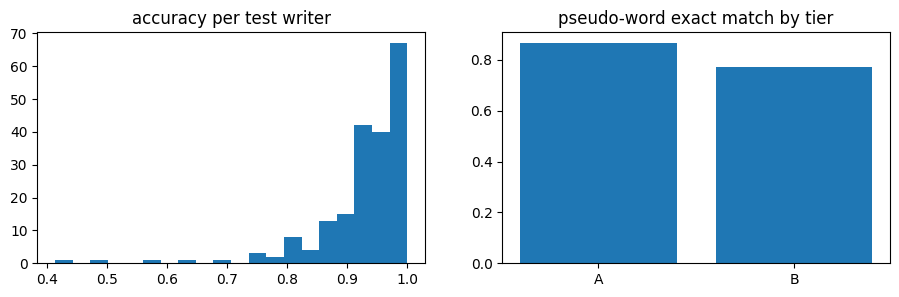

3733

In [10]:
def edit(a, b):
    d = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        p, d[0] = d[0], i
        for j, y in enumerate(b, 1): p, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, p + (x != y))
    return d[-1]

def seq_scores(pred, true):
    ov = sum(sum((Counter(p) & Counter(t)).values()) for p, t in zip(pred, true)); np_, nt = sum(map(len, pred)), sum(map(len, true))
    pr, rc = ov / max(np_, 1), ov / max(nt, 1)
    return dict(exact=float(np.mean([p == t for p, t in zip(pred, true)])), cer=float(sum(edit(p, t) for p, t in zip(pred, true)) / max(nt, 1)),
                f1=float(2 * pr * rc / max(pr + rc, 1e-9)), n=len(true))

tier = lambda ids: 'A' if isA(ids) else 'B'
ne = 200 if CFG['FAST'] else 1000; R = {}

# real glyphs: upright (as stored) and in their original slant (the stored glyphs were deslanted; a canvas drawing is not)
tg_ = np.random.default_rng(1).choice(te, min(len(te), 20000), replace=False); yt = Y[tg_]
def ece_(conf, ok, n=15):
    b = (conf * n).astype(int).clip(max=n - 1)
    return float(sum(abs(conf[b == i].mean() - ok[b == i].mean()) * (b == i).mean() for i in range(n) if (b == i).any()))
def glyph_probs(imgs):
    lg, ax = run(model, imgs), run_aux(model, imgs); pc = np.stack([char_probs(softmax(l, Tc))[1] for l in lg]); pa = softmax(np.stack(ax), Ta)
    return dict(ctc=pc, head=pa, blend=(1 - wa) * pc + wa * pa)
def gscore(P, y):
    ok = P.argmax(1) == y
    return dict(top1=float(ok.mean()), top3=float((np.argsort(-P, 1)[:, :3] == y[:, None]).any(1).mean()), macro_f1=macro_f1(P.argmax(1), y), ece=ece_(P.max(1), ok), n=len(y))
PU = glyph_probs([prep_line(X[i]) for i in tg_]); PS = glyph_probs([prep_line(reslant(X[i], float(SK[i]))) for i in tg_])
Pc = PU['blend']; top1 = Pc.argmax(1) == yt
R['Real glyphs (84 classes)'] = gscore(Pc, yt)
R['  CTC readout only'] = gscore(PU['ctc'], yt); R['  classifier head only'] = gscore(PU['head'], yt); R['  original slant (reconstructed)'] = gscore(PS['blend'], yt)
qd = df.quality.to_numpy()[tg_]; grp = lambda a, b: float(top1[(yt >= a) & (yt < b)].mean())
extra = dict(basic=grp(0, 50), numerals=grp(50, 60), compound=grp(60, 84), q_high=float(top1[qd >= 3].mean()) if (qd >= 3).any() else None,
             q_mid=float(top1[(qd > 1.5) & (qd < 3)].mean()) if ((qd > 1.5) & (qd < 3)).any() else None, q_low=float(top1[qd <= 1.5].mean()) if (qd <= 1.5).any() else None)
cm = np.bincount(yt * 84 + Pc.argmax(1), minlength=84 * 84).reshape(84, 84); np.fill_diagonal(cm, 0)
confused = [(CLASSES[i // 84], CLASSES[i % 84], int(cm.flat[i])) for i in np.argsort(-cm.flatten())[:10]]
per_writer = pd.Series(top1).groupby(WR[tg_]).mean()

# sequences
E = Synth(te, seed=5); en = lambda kind, n, eng=None: [(eng or E).sample(kind) for _ in range(n)]
def evaluate(samples, mode, lex=None, bonus_=0.):
    P = [softmax(l, T) for l in run(model, [s[0] for s in samples])]
    return [(rank(candidates(p, mode, lex), lex, bonus_, 1) or [((), 0.)])[0][0] for p in P], [tuple(s[1]) for s in samples]
nums, lexw, pw = en('num', ne), en('lex', ne, Synth(te, seed=6, pool=LEX_TEST)), en('pseudo', ne)
R['Numbers (1–8 digits)'] = seq_scores(*evaluate(nums, 'number'))
for a, b, nm in ((1, 4, '1–4'), (5, 8, '5–8')):
    sub = [s for s in nums if a <= len(s[1]) <= b]; R[f'  numbers {nm} digits'] = seq_scores(*evaluate(sub, 'number')) if sub else {}
pr_, tr_ = evaluate(lexw, 'word', LEXS, bonus); R['Held-out words, lexicon decoding'] = seq_scores(pr_, tr_)
for tn in 'AB':
    ix = [i for i, t in enumerate(tr_) if tier(t) == tn]; R[f'  tier {tn} (lexicon)'] = seq_scores([pr_[i] for i in ix], [tr_[i] for i in ix]) if ix else {}
pr_f, _ = evaluate(lexw, 'word'); R['Held-out words, free reading'] = seq_scores(pr_f, tr_)
pp_, tp_ = evaluate(pw, 'word'); R['Pseudo-words, free reading'] = seq_scores(pp_, tp_)
for tn in 'AB':
    ix = [i for i, t in enumerate(tp_) if tier(t) == tn]; R[f'  tier {tn} (pseudo)'] = seq_scores([pp_[i] for i in ix], [tp_[i] for i in ix]) if ix else {}

report = pd.DataFrame(R).T[['top1', 'top3', 'macro_f1', 'ece', 'exact', 'cer', 'f1', 'n']]; print(report.round(4).fillna('').to_string())
print('\nGlyph accuracy by group / form quality:', {k: (round(v, 4) if v is not None else None) for k, v in extra.items()})
print('Per-writer accuracy percentiles (5/25/50/75/95):', per_writer.quantile([.05, .25, .5, .75, .95]).round(3).tolist()); print('Top confusions (true → predicted, count):', confused)
TARGETS = [('Real glyph top-1 ≥ 96.5%', R['Real glyphs (84 classes)']['top1'] >= .965), ('Real glyph top-3 ≥ 99%', R['Real glyphs (84 classes)']['top3'] >= .99),
           ('Real glyph macro-F1 ≥ 0.96', R['Real glyphs (84 classes)']['macro_f1'] >= .96), ('Numbers exact ≥ 97%', R['Numbers (1–8 digits)']['exact'] >= .97),
           ('Numbers CER ≤ 1%', R['Numbers (1–8 digits)']['cer'] <= .01), ('Held-out words (lexicon) exact ≥ 95%', R['Held-out words, lexicon decoding']['exact'] >= .95),
           ('Free-reading word CER ≤ 3%', R['Pseudo-words, free reading']['cer'] <= .03)]
for k, ok in TARGETS: print('PASS' if ok else 'FAIL', k)

fig, ax = plt.subplots(1, 2, figsize=(11, 3)); ax[0].hist(per_writer, 20); ax[0].set_title('accuracy per test writer')
ax[1].bar(['A', 'B'], [R[f'  tier {t} (pseudo)'].get('exact', 0) for t in 'AB']); ax[1].set_title('pseudo-word exact match by tier'); plt.show()
json.dump(dict(results=R, glyph_groups=extra, calibration=CAL, accepted_coverage=dict(char=cov_char, number=cov_num, word=cov_word), confusions=confused,
               per_writer_quantiles=per_writer.quantile([.05, .25, .5, .75, .95]).tolist(), targets={k: bool(ok) for k, ok in TARGETS}), open(REL / 'metrics.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
(REL / 'report.html').write_text('<meta charset="utf-8"><h2>Test results (unseen writers)</h2>' + report.round(4).to_html()
                                 + '<ul>' + ''.join(f'<li>{"PASS" if ok else "FAIL"} {k}</li>' for k, ok in TARGETS) + '</ul>', encoding='utf-8')

## 8 · Export: ONNX, int8, parity, end-to-end test of the shipped bundle

In [11]:
import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic, QuantType
KW = {'dynamo': False} if 'dynamo' in inspect.signature(torch.onnx.export).parameters else {}
m_cpu = CRNN(); m_cpu.load_state_dict(torch.load(OUT / 'model3.pt', map_location='cpu')); m_cpu.eval()
f32 = REL / 'model3_crnn.onnx'; f8 = REL / 'model3_crnn.int8.onnx'
class Exp(nn.Module):
    """ONNX graph: CTC logits 'y' and classifier-head logits 'a' (mean over all frames) from one backbone pass."""
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, x): h = s.m.feats(x); return s.m.fc(h), s.m.aux(h.mean(1))
torch.onnx.export(Exp(m_cpu).eval(), torch.zeros(1, 1, 64, 256), f32, input_names=['x'], output_names=['y', 'a'], dynamic_axes={'x': {3: 'w'}, 'y': {1: 't'}}, opset_version=17, **KW)
try: quantize_dynamic(str(f32), str(f8), weight_type=QuantType.QInt8)
except Exception as e: print('int8 skipped:', e); f8 = f32
so = ort.SessionOptions(); so.intra_op_num_threads = 1
sess = lambda f: ort.InferenceSession(str(f), so, providers=['CPUExecutionProvider'])
onx = lambda s_, im: s_.run(None, {'x': im[None, None].astype(np.float32) / 255})[0][0]
sub = (nums[:100] + lexw[:100] + pw[:100]); imgs = [s[0] for s in sub]
ref = run(m_cpu.to(DEV), imgs); m_cpu.cpu()
def exact_on(f):
    s_ = sess(f); return np.mean([greedy(softmax(onx(s_, im))) == tuple(s[1]) for im, s in zip(imgs, sub)])
s32 = sess(f32); agree = np.mean([greedy(softmax(r_)) == greedy(softmax(onx(s32, im))) for r_, im in zip(ref, imgs)])
def latency(f, im, n=30):
    s_ = sess(f); onx(s_, im); t0 = time.perf_counter()
    for _ in range(n): onx(s_, im)
    return (time.perf_counter() - t0) / n * 1000
im256 = cv2.resize(imgs[100], (256, 64)); files = [f32] + ([f8] if f8 != f32 else [])
acc_ = {f: exact_on(f) for f in files}; lat_ = {f: latency(f, im256) for f in files}
ship = min([f for f in files if acc_[f] >= max(acc_.values()) - .005], key=lat_.get)        # fastest file that is as accurate
print(f'ONNX vs PyTorch greedy agreement {agree:.4f} · ' + ' · '.join(f'{f.name}: exact {acc_[f]:.3f}, {lat_[f]:.1f} ms' for f in files)
      + f' (1 thread, 64×256) → ship {ship.name} ({ship.stat().st_size / 1e6:.1f} MB)')

(REL / 'config.json').write_text(json.dumps(dict(model=ship.name, **CAL), indent=1), encoding='utf-8')
(REL / 'labels.json').write_text(json.dumps(dict(classes=CLASSES, vocab=VOCAB), ensure_ascii=False, indent=1), encoding='utf-8')
(REL / 'lexicon.txt').write_text('\n'.join(LEX), encoding='utf-8'); shutil.copy('inference.py', REL / 'inference.py'); torch.save(m_cpu.state_dict(), REL / 'model3.pt')

# End-to-end through the shipped Recognizer (ONNX, numpy, OpenCV only)
rec = Recognizer(REL); print('real glyphs  :', np.mean([rec.predict(X[i], 'char')['text'] == CLASSES[Y[i]] for i in np.random.default_rng(2).choice(te, min(300, len(te)), replace=False)]), '(top-1, shipped path, random test glyphs)')
print('numbers      :', np.mean([rec.predict(s[0], 'number')['text'] == s[3] for s in nums[:200]]))
print('lexicon words:', np.mean([rec.predict(s[0], 'word')['text'] == N(s[3]) for s in lexw[:200]]))
for s in (lexw[0], nums[0], pw[0]): print(s[3], '->', rec.predict(s[0]))
print('blank canvas ->', rec.predict(np.zeros((80, 80), np.uint8)))
if CFG['GOLDEN']:
    g = [(p.stem.rsplit('_', 1)[0], cv2.imread(str(p), cv2.IMREAD_UNCHANGED)) for p in Path(CFG['GOLDEN']).glob('*.png')]
    print(f'Golden set ({len(g)} real drawings): exact match {np.mean([rec.predict(im)["text"] == N(t) for t, im in g]):.3f}')
print('\nrelease/:', sorted(p.name for p in REL.iterdir()))

/tmp/ipykernel_23/3459763503.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(Exp(m_cpu).eval(), torch.zeros(1, 1, 64, 256), f32, input_names=['x'], output_names=['y', 'a'], dynamic_axes={'x': {3: 'w'}, 'y': {1: 't'}}, opset_version=17, **KW)
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset9.py:4571: UserWarning: Exporting a model to ONNX with a batch_size other than 1, with a variable length with GRU can cause an error when running the ONNX model with a different batch size. Make sure to save the model with a batch size of 1, or define the initial states (h0/c0) as inputs of the model. 

ONNX vs PyTorch greedy agreement 1.0000 · model3_crnn.onnx: exact 0.883, 8.7 ms · model3_crnn.int8.onnx: exact 0.887, 64.9 ms (1 thread, 64×256) → ship model3_crnn.onnx (6.9 MB)
real glyphs  : 0.9066666666666666 (top-1, shipped path, random test glyphs)
numbers      : 0.945
lexicon words: 0.95
দুঃখ -> {'text': 'দুঃখ', 'top3': [('দুঃখ', 0.5169031292413986), ('দুখ', 0.40095468760579916), ('দুঃখখ', 0.020609630351420993)], 'confidence': 0.5169031292413986, 'decision': 'suggest'}
০৮৪৫৬২ -> {'text': '০৮৪৫৬২', 'top3': [('০৮৪৫৬২', 0.9951097559339764), ('০৮৫৫৬২', 0.0013762247509490173), ('০৮৫৬২', 0.0005166417697220958)], 'confidence': 0.9951097559339764, 'decision': 'accept'}
ধবি -> {'text': 'ধবি', 'top3': [('ধবি', 0.7624114763408238), ('ধরি', 0.11928018505278776), ('ধঝি', 0.026525286741229327)], 'confidence': 0.7624114763408238, 'decision': 'suggest'}
blank canvas -> {'text': '', 'top3': [], 'confidence': 0.0, 'decision': 'reject'}

release/: ['config.json', 'inference.py', 'labels.json', 'lex